In [ ]:
# Import the libraries required
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Load the data
df = pd.read_csv('bank_fd_data.csv')
df.head

<bound method NDFrame.head of          Account_Name  Account_Age_Months  Fixed_Deposit_USD  Interest_Rate_%  \
0          Sean Payne                39.0             4839.0             3.95   
1           Karen Fox                52.0             9551.0             4.51   
2    Lauren Garcia MD                29.0             3376.0             3.71   
3       Kyle Jennings                15.0             4009.0             2.73   
4     Valerie Montoya                43.0             2827.0             4.34   
..                ...                 ...                ...              ...   
995       Hannah Rose                 4.0             9584.0             1.76   
996          Helen Wu                 1.0             1630.0             1.89   
997  Kimberly Bradley                49.0             7683.0             4.42   
998     Sandra Wilson                40.0             1277.0             4.19   
999        Craig Gray                32.0             1232.0             3.61  

In [ ]:
# Check for missing values
df.isnull().sum()

Account_Name           0
Account_Age_Months     1
Fixed_Deposit_USD      1
Interest_Rate_%        0
Account_Balance_USD    0
dtype: int64

In [ ]:
# Treating the missing values
# Account_Age_Months to be filled with mean
# Fixed_Deposit_USD to be filled forward fill
df['Account_Age_Months'] = df['Account_Age_Months'].fillna(df['Account_Age_Months'].mean())
df['Fixed_Deposit_USD'] = df['Fixed_Deposit_USD'].fillna(method='ffill')
df.isnull().sum()

Account_Name           0
Account_Age_Months     0
Fixed_Deposit_USD      0
Interest_Rate_%        0
Account_Balance_USD    0
dtype: int64

In [ ]:
# Check for datatypes
df.dtypes

Account_Name            object
Account_Age_Months     float64
Fixed_Deposit_USD      float64
Interest_Rate_%        float64
Account_Balance_USD    float64
dtype: object

In [ ]:
## Note to student: For this model there is no requirement to transform the "Account_Name"
  ## variable into nominal dummy variables, still to learn how to transform, we will try this

# Label Encoder (Converting the categorical variables into dummy nominal variables)
le = LabelEncoder()
df['Account_Name_Encoded'] = le.fit_transform(df['Account_Name'])
df.head

<bound method NDFrame.head of          Account_Name  Account_Age_Months  Fixed_Deposit_USD  Interest_Rate_%  \
0          Sean Payne                39.0             4839.0             3.95   
1           Karen Fox                52.0             9551.0             4.51   
2    Lauren Garcia MD                29.0             3376.0             3.71   
3       Kyle Jennings                15.0             4009.0             2.73   
4     Valerie Montoya                43.0             2827.0             4.34   
..                ...                 ...                ...              ...   
995       Hannah Rose                 4.0             9584.0             1.76   
996          Helen Wu                 1.0             1630.0             1.89   
997  Kimberly Bradley                49.0             7683.0             4.42   
998     Sandra Wilson                40.0             1277.0             4.19   
999        Craig Gray                32.0             1232.0             3.61  

In [ ]:
# Exploration Data Analysis (EDA)
df.describe()

,Account_Age_Months,Fixed_Deposit_USD,Interest_Rate_%,Account_Balance_USD,Account_Name_Encoded
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,31.194194,5412.483000,3.575390,6840.592570,497.13400
std,17.371935,2572.774868,0.892296,2725.691563,286.50274
min,1.000000,1006.000000,1.680000,1599.230000,0.00000
25%,17.000000,3096.750000,2.850000,4425.520000,249.75000
50%,32.000000,5428.500000,3.595000,6893.090000,497.50000
75%,47.000000,7581.500000,4.310000,9153.257500,745.25000
max,60.000000,9988.000000,5.500000,12284.320000,992.00000


<AxesSubplot:>

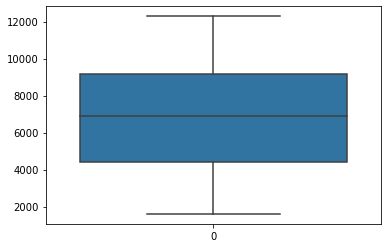

In [ ]:
## Test for outliers (using box plot)
sns.boxplot(data=df['Account_Balance_USD'])

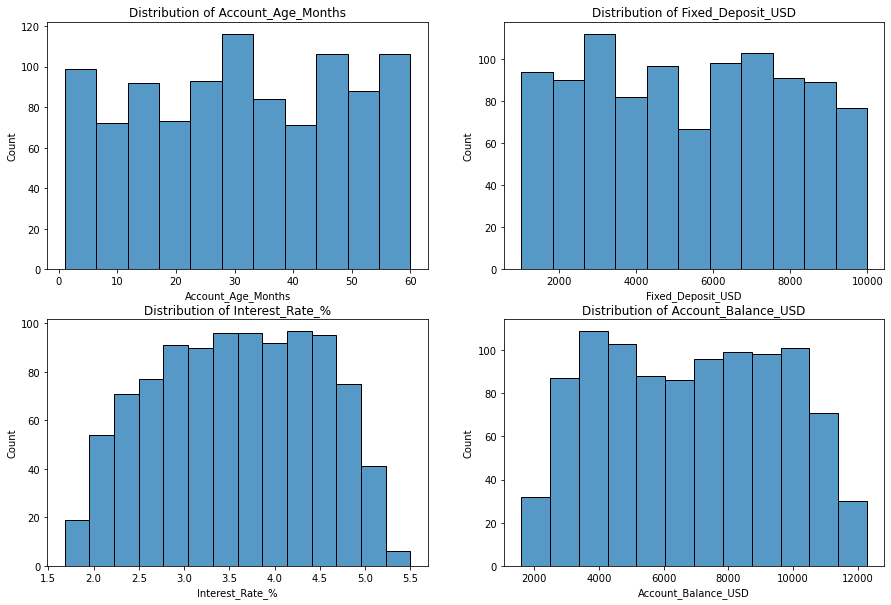

In [ ]:
# Data Visualisation  (Histogram) to test the distribution of the data (normality)

plt.figure(figsize=(15, 10))
for i, column in enumerate(['Account_Age_Months', 'Fixed_Deposit_USD',
                            'Interest_Rate_%', 'Account_Balance_USD']):
    plt.subplot(2,2, i+1)
    sns.histplot(data = df, x=column)
    plt.title(f'Distribution of {column}')
plt.show()

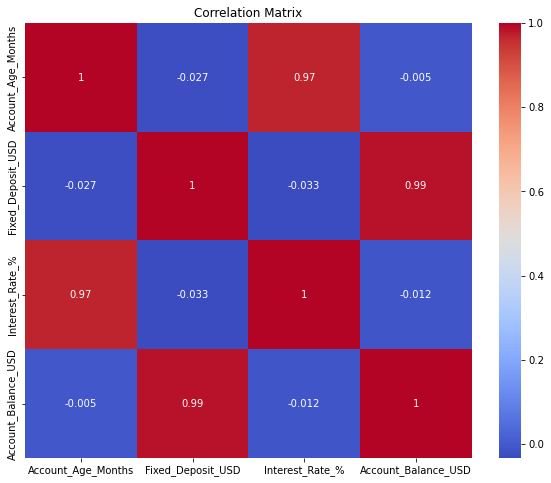

In [ ]:
# Data Visualisation  (Correlation Matrix)
correlation_matrix = df [ ['Account_Age_Months', 'Fixed_Deposit_USD',
                            'Interest_Rate_%', 'Account_Balance_USD']].corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix, cmap = 'coolwarm', annot=True)
plt.title('Correlation Matrix')
plt.show()

In [ ]:
# Define X and Y variables
X = df[['Account_Age_Months', 'Fixed_Deposit_USD','Interest_Rate_%']]
y = df['Account_Balance_USD']

In [ ]:
# Split the data into training and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)
X.shape, y.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1000, 3), (1000,), (800, 3), (200, 3), (800,), (200,))

In [ ]:
# Define the model and estimate the parameters
model = LinearRegression()

In [ ]:
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
# Evaluate the model
y_pred = model.predict(X_test)

In [ ]:
# Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"RSQ: {r2:.2f}")

MSE: 200069.93
RMSE: 447.29
RSQ: 0.97


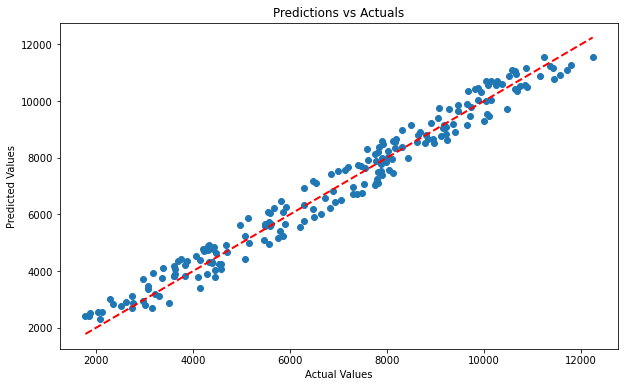

In [ ]:
# Evlauation of the model (Plot predictions & actuals)
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Predictions vs Actuals')
plt.show()

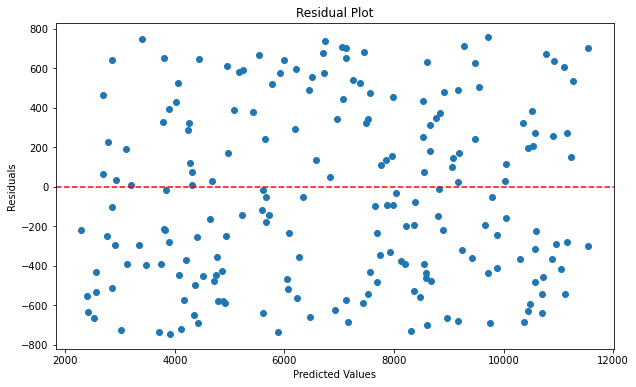

In [ ]:
# Evaluation of the model (Check the distribution of residuals / errors)
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

In [ ]:
# Feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
print("\nFeature Importance:")
print(feature_importance)


Feature Importance:
              Feature  Coefficient
0  Account_Age_Months     0.792542
1   Fixed_Deposit_USD     1.043895
2     Interest_Rate_%    44.193741


In [ ]:
def predict_account_balance(age_months, deposit_usd, interest_rate):
   # Scale inputs (using same scaler fitted earlier)
   input_scaled = scaler.transform([[age_months, deposit_usd, interest_rate]])

   # Predict
   prediction = model.predict(input_scaled)[0]

   return prediction

# Example usage
age = 30
deposit = 5000
interest = 3.5

predicted_balance = predict_account_balance(age, deposit, interest)
print(f"Predicted Account Balance: ${predicted_balance:,.2f}")

# Interactive testing
while True:
   try:
       print("\nAccount Balance Predictor")
       age = float(input("Enter Account Age (months, 1-60): "))
       deposit = float(input("Enter Fixed Deposit (USD, 1000-10000): "))
       interest = float(input("Enter Interest Rate (%, 1.5-5.5): "))

       balance = predict_account_balance(age, deposit, interest)
       print(f"\nPredicted Balance: ${balance:,.2f}")

       if input("\nTry another? (y/n): ").lower() != 'y':
           break

   except ValueError:
       print("Please enter valid numbers")

Predicted Account Balance: $1,013.81

Account Balance Predictor
Enter Account Age (months, 1-60): 20
Enter Fixed Deposit (USD, 1000-10000): 5000
Enter Interest Rate (%, 1.5-5.5): 3

Predicted Balance: $988.58
